In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# Inspect the dataset
display(df.head())
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,09-05-2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


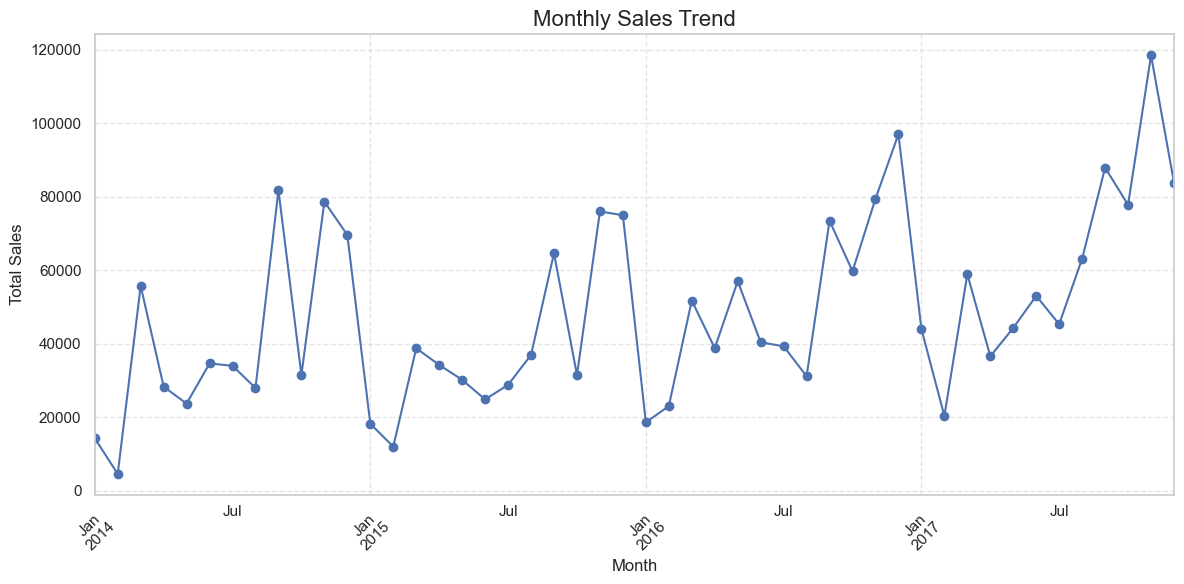

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert dates with mixed formats
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    errors="coerce"
)

# Remove rows where dates could not be parsed
df = df.dropna(subset=["Order Date"])

# Calculate total sales for each month
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

# Plot monthly sales trend
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [3]:
# Identify the highest and lowest sales months
monthly_sales = monthly_sales.sort_index()

print("Highest sales month:", monthly_sales.idxmax())
print("Highest monthly sales:", round(monthly_sales.max(), 2))

print("Lowest sales month:", monthly_sales.idxmin())
print("Lowest monthly sales:", round(monthly_sales.min(), 2))

Highest sales month: 2017-11
Highest monthly sales: 118447.82
Lowest sales month: 2014-02
Lowest monthly sales: 4519.89


### Observation: Monthly Sales Trend

The monthly sales analysis shows variations in sales throughout the study period. The highest monthly sales occurred in **November 2017**, reaching **118,447.82**, while the lowest monthly sales occurred in **February 2014**, at **4,519.89**.

### Business Insight

The substantial difference between the highest- and lowest-performing months suggests that sales varied considerably over time. These variations may be associated with seasonal demand, promotions, or changes in customer purchasing behavior.

### Business Recommendation

The business should investigate the factors behind the strong sales performance in November 2017 and compare monthly trends across multiple years. This can help improve inventory planning, promotional timing, and resource allocation.

Total Sales by Category:


Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


Highest-selling category: Technology
Highest sales: 836154.03

Lowest-selling category: Office Supplies
Lowest sales: 719047.03


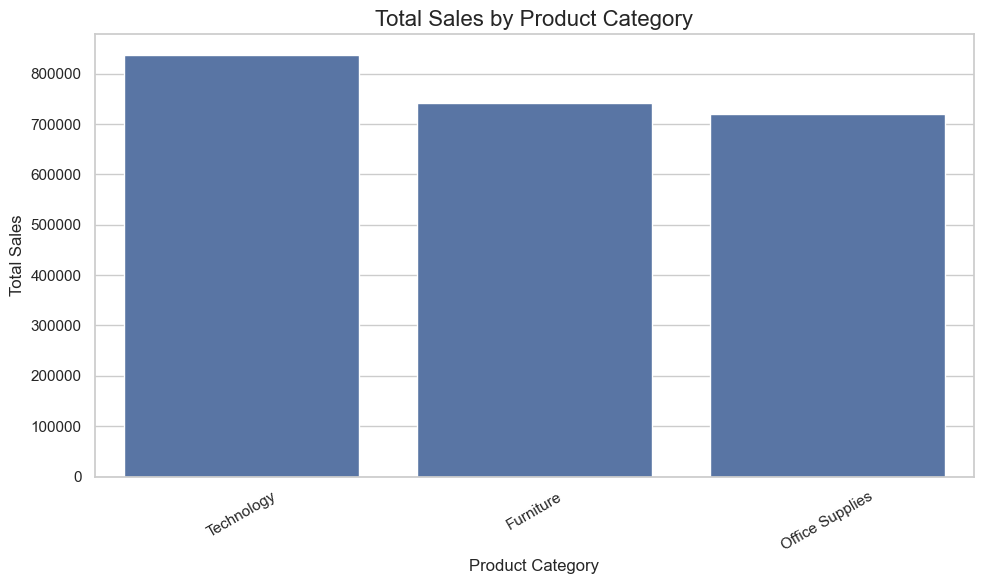

In [4]:
# Calculate total sales by product category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(
    ascending=False
)

# Display the actual sales values
print("Total Sales by Category:")
display(category_sales)

# Identify the highest and lowest categories
print("\nHighest-selling category:", category_sales.idxmax())
print("Highest sales:", round(category_sales.max(), 2))

print("\nLowest-selling category:", category_sales.idxmin())
print("Lowest sales:", round(category_sales.min(), 2))

# Create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title("Total Sales by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation: Sales by Product Category

The analysis shows that **[Technology]** generated the highest total sales, while **[Office Supplies]** generated the lowest total sales.

### Business Insight

The differences in sales across categories indicate that some product categories contribute more to overall revenue than others.

### Business Recommendation

Maintain adequate inventory for high-performing categories and investigate lower-performing categories to understand customer demand, pricing, and product availability. Consider targeted promotions only where the data supports them.

Profit by Sub-Category:


Sub-Category
Tables        -17725.48
Bookcases      -3472.56
Supplies       -1189.10
Fasteners        949.52
Machines        3384.76
Labels          5546.25
Art             6527.79
Envelopes       6964.18
Furnishings    13059.14
Appliances     18138.01
Storage        21278.83
Chairs         26590.17
Binders        30221.76
Paper          34053.57
Accessories    41936.64
Phones         44515.73
Copiers        55617.82
Name: Profit, dtype: float64


Most profitable sub-category: Copiers
Highest total profit: 55617.82

Lowest-profit sub-category: Tables
Lowest total profit: -17725.48


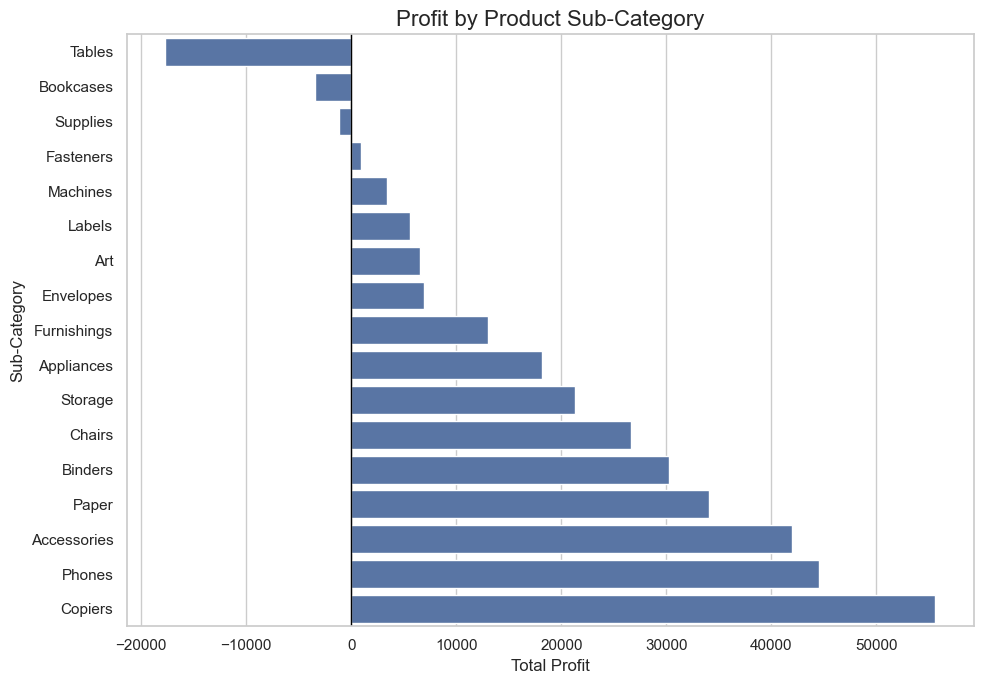

In [5]:
# Calculate total profit by sub-category
profit = df.groupby("Sub-Category")["Profit"].sum().sort_values(
    ascending=True
)

# Display actual profit values
print("Profit by Sub-Category:")
display(profit.round(2))

print("\nMost profitable sub-category:", profit.idxmax())
print("Highest total profit:", round(profit.max(), 2))

print("\nLowest-profit sub-category:", profit.idxmin())
print("Lowest total profit:", round(profit.min(), 2))

# Create horizontal bar chart
plt.figure(figsize=(10, 7))
sns.barplot(x=profit.values, y=profit.index)

plt.axvline(0, color="black", linewidth=1)
plt.title("Profit by Product Sub-Category", fontsize=16)
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

### Observation: Profit by Sub-Category

The analysis compares total profit across product sub-categories. **[Copiers]** generated the highest total profit, while **[Tables]** recorded the lowest total profit.

### Business Insight

Differences in profitability suggest that product categories contribute differently to the business's overall financial performance. A low-profit sub-category should be examined further to understand the factors affecting its performance.

### Business Recommendation

Review pricing, discount levels, shipping costs, and demand for low-profit sub-categories. Maintain the performance of profitable products and test targeted improvements for underperforming products.

,Sales,Quantity,Discount,Profit
Sales,1.00,0.20,-0.03,0.48
Quantity,0.20,1.00,0.01,0.07
Discount,-0.03,0.01,1.00,-0.22
Profit,0.48,0.07,-0.22,1.00


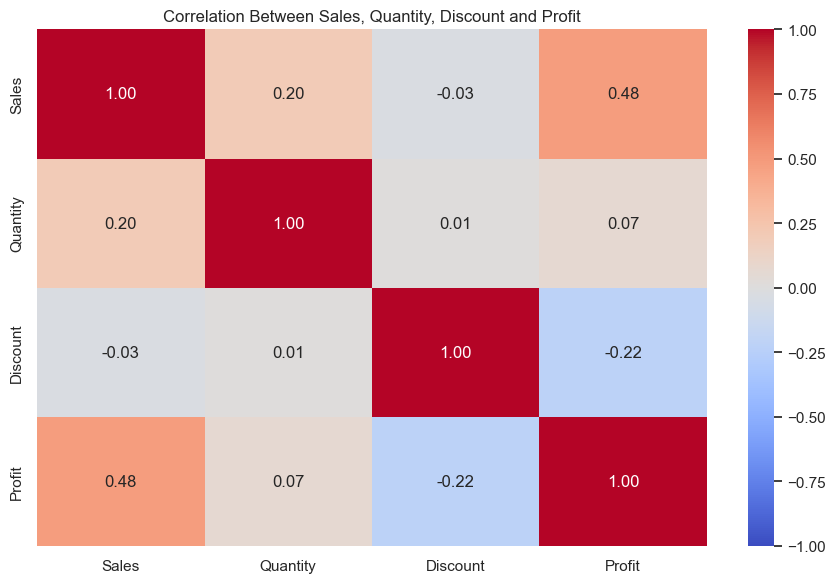

In [6]:
# Select numerical columns
numeric = df[["Sales", "Quantity", "Discount", "Profit"]]

# Calculate correlation
correlation = numeric.corr()

# Display correlation values
display(correlation.round(2))

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sales, Quantity, Discount and Profit")
plt.tight_layout()
plt.show()

### Observation: Correlation Heatmap

The correlation heatmap shows the relationships between Sales, Quantity, Discount, and Profit.

Sales and Profit have a moderate positive correlation of **0.48**, suggesting that transactions with higher sales tend to be associated with higher profits. Sales and Quantity have a weak positive correlation of **0.20**.

Discount and Profit show a negative correlation of **−0.22**, indicating that higher discounts tend to be associated with lower profits in this dataset. Sales and Discount have a correlation of **−0.03**, indicating almost no linear relationship between these two variables.

Quantity and Profit have a weak positive correlation of **0.07**, while Quantity and Discount have almost no linear correlation at **0.01**.

### Business Insight

The negative relationship between Discount and Profit suggests that discounting may be associated with reduced profitability. However, correlation alone cannot establish that discounts cause profits to decline.

### Business Recommendation

The business should evaluate discount policies by examining profit margins across discount levels, product categories, and customer segments. Promotional strategies should be assessed based on their impact on profitability rather than sales revenue alone.

## Conclusion

Exploratory Data Analysis was performed on the retail sales dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis examined monthly sales trends, sales by product category, profit by sub-category, and correlations among key numerical variables.

The correlation analysis identified a moderate positive relationship between Sales and Profit and a weak negative relationship between Discount and Profit. The visualizations also provide a basis for identifying differences in product performance and changes in monthly sales.

These insights can help the business evaluate promotional strategies, improve inventory planning, and monitor product profitability. Further analysis is recommended to investigate the factors influencing sales and profit.

Overall, this project demonstrates how exploratory data analysis can turn retail transaction data into useful business insights.